# Car Price ML Assignment - Full Solution
Proper Train/Test Split BEFORE Preprocessing

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns


In [2]:
df = pd.read_csv('car__price.csv')  
df.head()


,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,Make
0,A1,2017.0,12500.0,Manual,15735.0,Petrol,150.0,55.4,1.4,audi
1,A6,2016.0,16500.0,Automatic,36203.0,Diesel,20.0,64.2,2.0,audi
2,A1,2016.0,11000.0,Manual,29946.0,Petrol,30.0,55.4,1.4,audi
3,A4,2017.0,16800.0,Automatic,25952.0,Diesel,145.0,67.3,2.0,audi
4,A3,2019.0,17300.0,Manual,1998.0,Petrol,145.0,49.6,1.0,audi


## EDA

In [3]:

print(df.shape)
print(df.info())
print(df.isnull().sum())


(72435, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72435 entries, 0 to 72434
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         68814 non-null  object 
 1   year          68813 non-null  float64
 2   price         68814 non-null  float64
 3   transmission  68812 non-null  object 
 4   mileage       68813 non-null  float64
 5   fuelType      68813 non-null  object 
 6   tax           68814 non-null  float64
 7   mpg           68814 non-null  float64
 8   engineSize    68813 non-null  float64
 9   Make          68814 non-null  object 
dtypes: float64(6), object(4)
memory usage: 5.5+ MB
None
model           3621
year            3622
price           3621
transmission    3623
mileage         3622
fuelType        3622
tax             3621
mpg             3621
engineSize      3622
Make            3621
dtype: int64


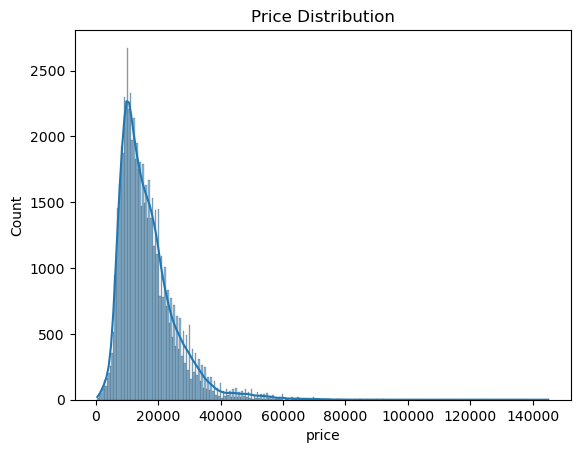

In [4]:

plt.figure()
sns.histplot(df['price'], kde=True)
plt.title("Price Distribution")
plt.show()


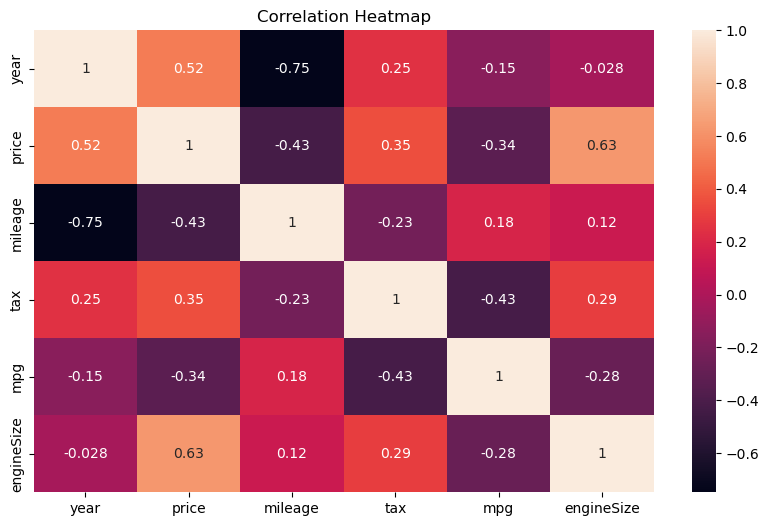

In [5]:

plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.title("Correlation Heatmap")
plt.show()


## Train/Test Split BEFORE Preprocessing

In [6]:
Y = df["price"]
X = df.drop("price", axis=1)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)


In [8]:
X_train.isna().sum()


model              0
year            2872
transmission    2929
mileage         2921
fuelType        2899
tax             2889
mpg             2874
engineSize      2929
Make            2881
dtype: int64

In [9]:
X_test.isna().sum()

model           3621
year             750
transmission     694
mileage          701
fuelType         723
tax              732
mpg              747
engineSize       693
Make             740
dtype: int64

In [10]:
y_train.isna().sum()

np.int64(2914)

In [11]:
y_test.isna().sum()

np.int64(707)

In [12]:
for col in [ "year", "transmission", "mileage", "fuelType", "tax", "mpg", "engineSize", "Make"]:
    X_train[col] = X_train[col].ffill()
    X_test[col] = X_test[col].ffill()

y_train = y_train.ffill()
y_test = y_test.ffill()

In [13]:
categorical_col_train = X_train[[ 'fuelType', 'transmission', 'Make']]
categorical_col_test = X_test[[ 'fuelType', 'transmission', 'Make']]

numerical_col_train = pd.concat([X_train, y_train], axis=1)
numerical_col_train = numerical_col_train[['year', 'engineSize', 'mileage', 'tax', 'mpg', 'price']]

numerical_col_test = pd.concat([X_test, y_test], axis=1)
numerical_col_test = numerical_col_test[['year', 'engineSize', 'mileage', 'tax', 'mpg', 'price']]

#### What does the distribution of car prices look like? 

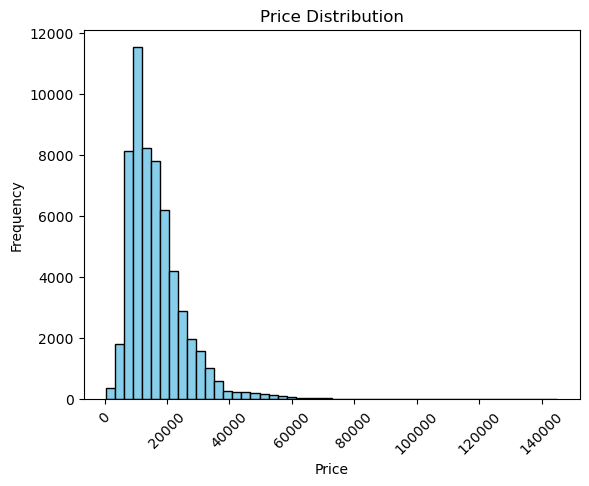

In [14]:
plt.hist(y_train,bins=50 , color='skyblue', edgecolor='black')
plt.xticks(rotation=45)
plt.title('Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

#### Detecting outliers
Using Box Plot

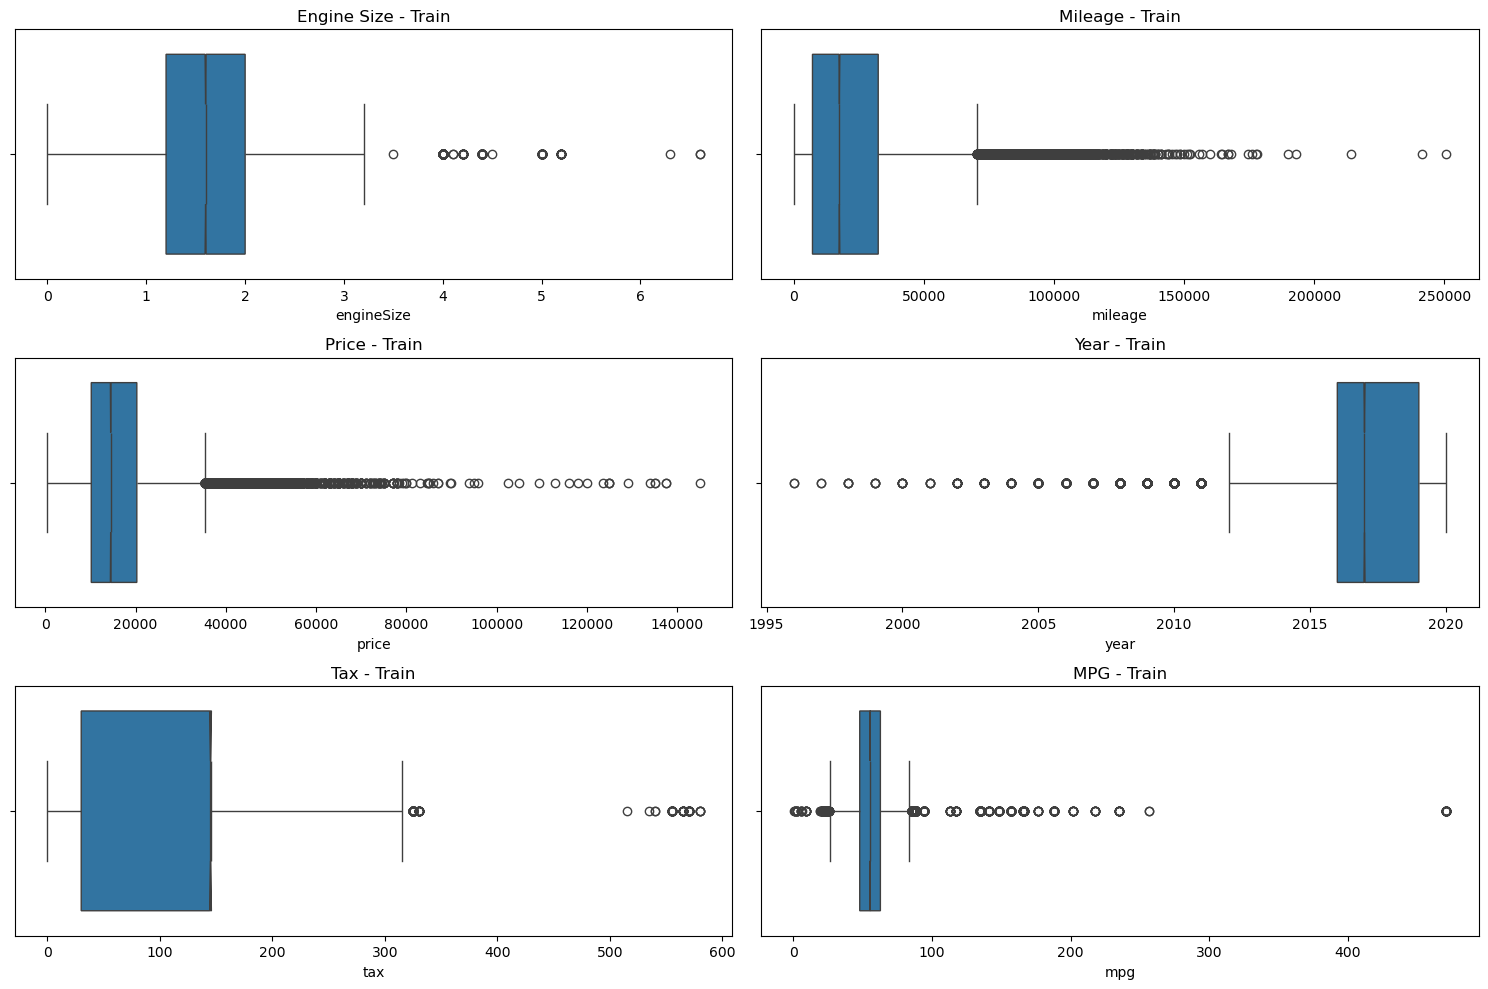

In [15]:
fig, axes = plt.subplots(3, 2, figsize=(15, 10))

sns.boxplot(x=X_train['engineSize'], notch=True, patch_artist=True, ax=axes[0,0]).set_title('Engine Size - Train')
sns.boxplot(x=X_train['mileage'], notch=True, patch_artist=True, ax=axes[0,1]).set_title('Mileage - Train')
sns.boxplot(x=y_train, notch=True, patch_artist=True, ax=axes[1,0]).set_title('Price - Train')
sns.boxplot(x=X_train['year'], notch=True, patch_artist=True, ax=axes[1,1]).set_title('Year - Train')
sns.boxplot(x=X_train['tax'], notch=True, patch_artist=True, ax=axes[2,0]).set_title('Tax - Train')
sns.boxplot(x=X_train['mpg'], notch=True, patch_artist=True, ax=axes[2,1]).set_title('MPG - Train')

plt.tight_layout()
plt.show()

### Handling outliers

 using Capping way

In [16]:
for col in numerical_col_train.columns[0:6]:
    q1 = numerical_col_train[col].quantile(0.25)
    q3 = numerical_col_train[col].quantile(0.75)
    IQR = q3 - q1
    LB = q1 - 1.5 * IQR
    UB = q3 + 1.5 * IQR
    
    X_train[col] = np.clip(numerical_col_train[col], LB, UB)
    X_test[col] = np.clip(numerical_col_test[col], LB, UB)  # use same LB, UB from train
    
    print(f"Capping applied to: {col}")

q1_y = y_train.quantile(0.25)
q3_y = y_train.quantile(0.75)
IQR_y = q3_y - q1_y
LB_y = q1_y - 1.5 * IQR_y
UB_y = q3_y + 1.5 * IQR_y

y_train = np.clip(y_train, LB_y, UB_y)
y_test = np.clip(y_test, LB_y, UB_y)

print("Capping applied to: price")

Capping applied to: year
Capping applied to: engineSize
Capping applied to: mileage
Capping applied to: tax
Capping applied to: mpg
Capping applied to: price
Capping applied to: price


#### Box plots after handling outlires

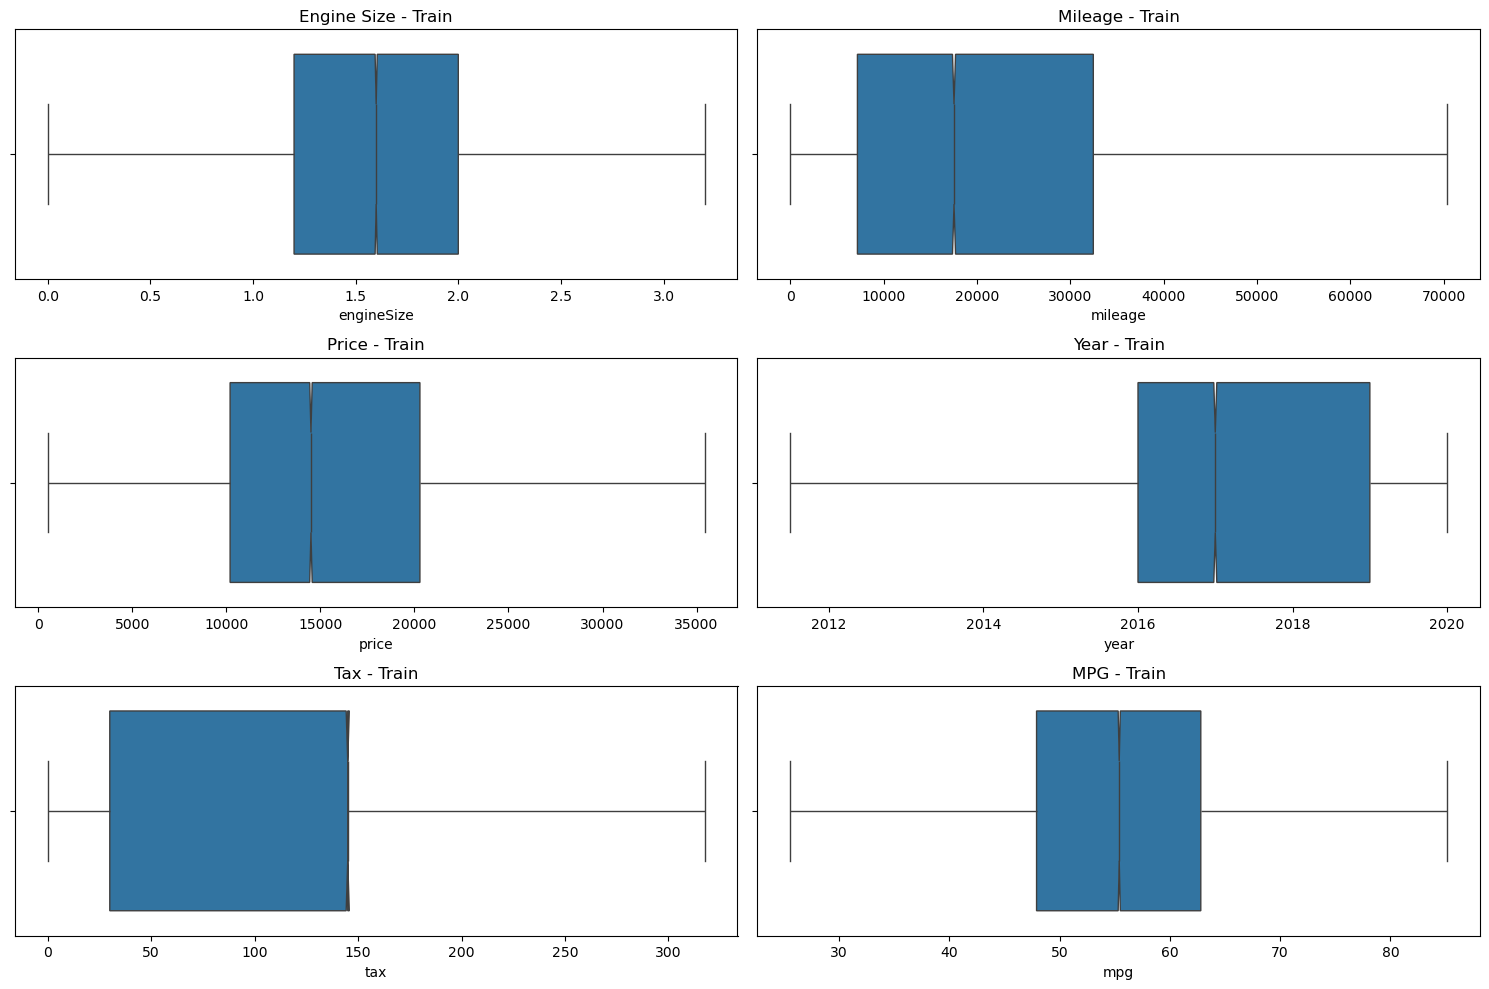

In [17]:
fig, axes = plt.subplots(3, 2, figsize=(15, 10))

sns.boxplot(x=X_train['engineSize'], notch=True, patch_artist=True, ax=axes[0,0]).set_title('Engine Size - Train')
sns.boxplot(x=X_train['mileage'], notch=True, patch_artist=True, ax=axes[0,1]).set_title('Mileage - Train')
sns.boxplot(x=y_train, notch=True, patch_artist=True, ax=axes[1,0]).set_title('Price - Train')
sns.boxplot(x=X_train['year'], notch=True, patch_artist=True, ax=axes[1,1]).set_title('Year - Train')
sns.boxplot(x=X_train['tax'], notch=True, patch_artist=True, ax=axes[2,0]).set_title('Tax - Train')
sns.boxplot(x=X_train['mpg'], notch=True, patch_artist=True, ax=axes[2,1]).set_title('MPG - Train')

plt.tight_layout()
plt.show()

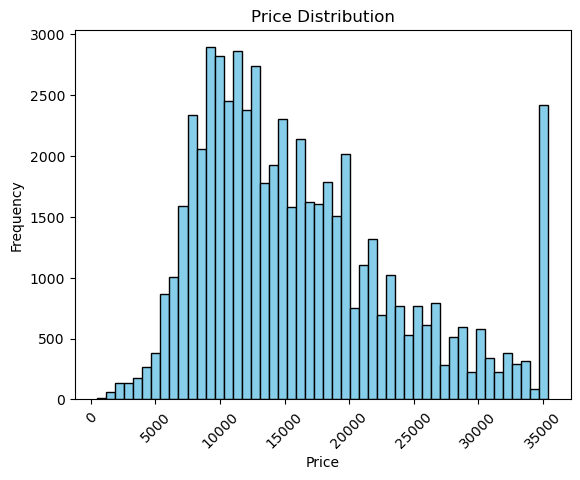

In [18]:
plt.hist(y_train,bins=50 , color='skyblue', edgecolor='black')
plt.xticks(rotation=45)
plt.title('Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

#### Which features seem most related to price? 
Its Engine Size

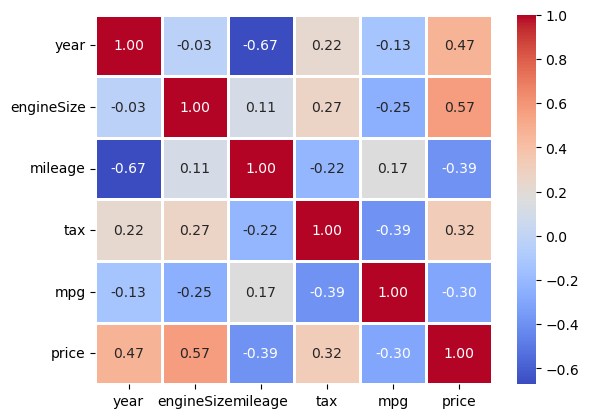

In [19]:
corr = numerical_col_train.corr(method='pearson')

sns.heatmap(corr, cmap="coolwarm", fmt=".2f", annot=True, linewidths=True)
plt.show()

#### Encode categorical columns
I used OneHotEncoder, since order is not important in those categorical featuers 

In [20]:
encoder = OneHotEncoder(sparse_output=False)
encoded_train = encoder.fit_transform(categorical_col_train)
encoded_test = encoder.transform(categorical_col_test)

encoded_df_train = pd.DataFrame(encoded_train, columns=encoder.get_feature_names_out(categorical_col_train.columns))
encoded_df_test = pd.DataFrame(encoded_test, columns=encoder.get_feature_names_out(categorical_col_train.columns))

encoded_df_train
encoded_df_test

,fuelType_Diesel,fuelType_Electric,fuelType_Hybrid,fuelType_Other,fuelType_Petrol,transmission_Automatic,transmission_Manual,transmission_Other,transmission_Semi-Auto,Make_BMW,Make_Ford,Make_Hyundai,Make_audi,Make_skoda,Make_toyota,Make_vw
0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14482,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
14483,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
14484,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
14485,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


#### Scale numerical features
Using StandarScaler

In [21]:
cols_to_scale = [col for col in numerical_col_train.columns]

scaler = StandardScaler()
scaled_train = scaler.fit_transform(numerical_col_train[cols_to_scale])
scaled_test = scaler.transform(numerical_col_test[cols_to_scale])

df_scaled_train = pd.DataFrame(scaled_train, columns=cols_to_scale, index=numerical_col_train.index)
df_scaled_test = pd.DataFrame(scaled_test, columns=cols_to_scale, index=numerical_col_test.index)
df_scaled_train
df_scaled_test

,year,engineSize,mileage,tax,mpg,price
59074,-0.035508,-1.136444,-0.531610,0.437757,0.654771,-0.868717
9194,0.915992,2.437341,-0.790069,0.437757,-0.321605,2.520955
7979,-0.511258,0.650448,2.206107,-1.514344,0.866515,-0.492565
64571,0.915992,0.650448,-0.911455,0.437757,0.672416,-0.012554
3026,-0.035508,0.650448,0.331095,0.437757,-0.027516,0.369302
...,...,...,...,...,...,...
71183,-1.938508,0.114380,0.154927,0.437757,-0.421595,-0.900574
30658,-1.938508,-0.064309,1.646043,-1.514344,0.672416,-1.083968
20597,0.915992,0.650448,-0.996948,0.281589,3.360391,3.490663
1040,1.391742,-0.242998,-0.882392,0.515841,-0.909783,1.659950


## Task 3

### A. Regression Target (Linear Regression)
#### Use the dataset to train the model to predict the car prices

In [22]:
regression_target = Y

### B. Classification Target (KNN)
#### Use the dataset to train the model to classify the car prices into 3 categories: Cheap, Moderate, and Expensive.

#### Decide on the thresholds (price boundaries) for each category,and justify your thresholds — use the data distribution to support your decision.

In [23]:
q1 = Y.quantile(0.33)
q2 = Y.quantile(0.66)
def categorize_price(price):
    if price <= q1:
        return 'Cheap'
    elif price <= q2:
        return 'Moderate'
    else:
        return 'Expensive'


In [24]:
y_df = pd.DataFrame(Y)
y_df['price_category'] = y_df['price'].apply(categorize_price)

y_train_df = pd.DataFrame(y_train)
y_train_df['price_category'] = y_train_df['price'].apply(categorize_price)

y_test_df = pd.DataFrame(y_test)
y_test_df['price_category'] = y_test_df['price'].apply(categorize_price)

#### Show how many cars fall into each category after splitting.

In [25]:
category_counts = y_train_df['price_category'].value_counts()
print("\nNumber of cars in each category:")
print(category_counts)


Number of cars in each category:
price_category
Moderate     19448
Expensive    19431
Cheap        19069
Name: count, dtype: int64


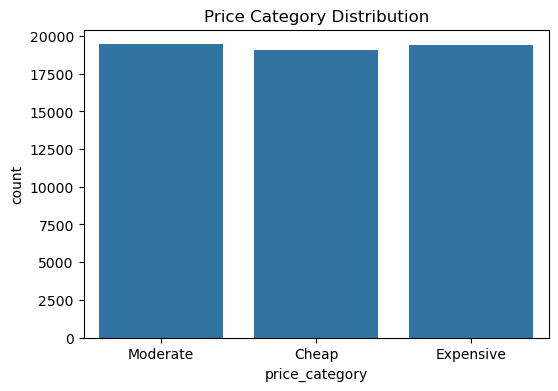

In [26]:
plt.figure(figsize=(6,4))
sns.countplot(x='price_category', data=y_train_df)
plt.title('Price Category Distribution')
plt.show()

#### Encode Target for KNN

In [27]:
le = LabelEncoder()
y_train['price_category_encoded'] = le.fit_transform(y_train_df['price_category'])
y_test['price_category_encoded'] = le.transform(y_test_df['price_category'])

print("\nEncoded Classes Mapping:")
for i, label in enumerate(le.classes_):
    print(f"{label} -> {i}")


Encoded Classes Mapping:
Cheap -> 0
Expensive -> 1
Moderate -> 2


## TASK 4
### Model 1: Linear Regression

In [28]:
X_train=df_scaled_train.drop('price', axis=1)
y_train=df_scaled_train['price']
x_test=df_scaled_test.drop('price', axis=1)
y_test=df_scaled_test['price']

In [29]:
Y=y_test

In [30]:
df_scaled_test.head()

,year,engineSize,mileage,tax,mpg,price
59074,-0.035508,-1.136444,-0.531610,0.437757,0.654771,-0.868717
9194,0.915992,2.437341,-0.790069,0.437757,-0.321605,2.520955
7979,-0.511258,0.650448,2.206107,-1.514344,0.866515,-0.492565
64571,0.915992,0.650448,-0.911455,0.437757,0.672416,-0.012554
3026,-0.035508,0.650448,0.331095,0.437757,-0.027516,0.369302


Model fiting

In [31]:
model = LinearRegression()
model.fit(X_train, y_train)
y_hat = model.predict(x_test)

#### Evaluation

In [32]:
mae = mean_absolute_error(y_test, y_hat)
mse = mean_squared_error(y_test, y_hat)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_hat)

print("MAE  =", mae)
print("MSE  =", mse)
print("RMSE =", rmse)
print("R2   =", r2)

MAE  = 0.4116797011832595
MSE  = 0.408694656953418
RMSE = 0.6392923094746393
R2   = 0.6040975836106953


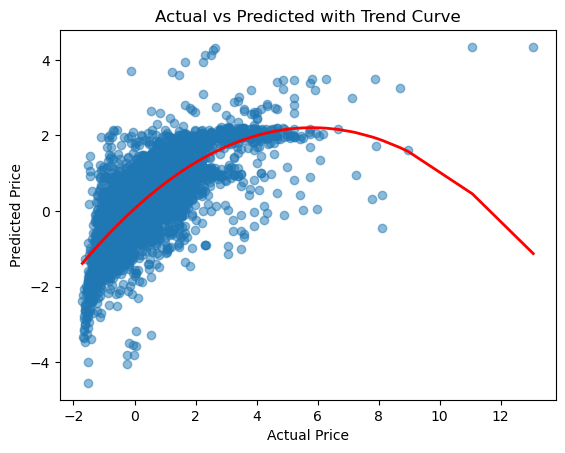

In [33]:

plt.scatter(y_test, y_hat, alpha=0.5)

sorted_idx = np.argsort(y_test)
x_sorted = y_test.iloc[sorted_idx]
y_sorted = y_hat[sorted_idx]

z = np.polyfit(x_sorted, y_sorted, 2)
p = np.poly1d(z)

plt.plot(x_sorted, p(x_sorted), color='red', linewidth=2)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted with Trend Curve")

plt.show()

## Classification Target

In [34]:
q1 = y_train.quantile(0.33)
q2 = y_train.quantile(0.66)

def categorize(price):
    if price <= q1:
        return "Cheap"
    elif price <= q2:
        return "Moderate"
    else:
        return "Expensive"

y_train_cat = y_train.apply(categorize)
y_test_cat = y_test.apply(categorize)


## KNN Classification

In [35]:

X_train_processed = pd.concat(
    [df_scaled_train.drop(columns=['price']).reset_index(drop=True), 
     encoded_df_train.reset_index(drop=True)], 
    axis=1
)
X_test_processed = pd.concat(
    [df_scaled_test.drop(columns=['price']).reset_index(drop=True), 
     encoded_df_test.reset_index(drop=True)], 
    axis=1
)

y_train_class = le.fit_transform(y_train_df['price_category'])
y_test_class = le.transform(y_test_df['price_category'])

In [37]:
knn = KNeighborsClassifier()
param_grid = {
    'n_neighbors': [3, 5, 7, 9], 
    'metric': ['euclidean', 'manhattan']  
}

grid_search = GridSearchCV(knn, param_grid, cv=5, scoring='accuracy' , n_jobs=-1)

grid_search.fit(X_train_processed, y_train_class)
best_knn = grid_search.best_estimator_
print(f"Best Parameters: {grid_search.best_params_}")


Best Parameters: {'metric': 'manhattan', 'n_neighbors': 7}


In [ ]:
y_pred_class = best_knn.predict(X_test_processed)

print("\n--- Evaluation Metrics ---")
print("Accuracy:", accuracy_score(y_test_class, y_pred_class))
print("Precision (Macro):", precision_score(y_test_class, y_pred_class, average='macro'))
print("Recall (Macro):", recall_score(y_test_class, y_pred_class, average='macro'))
print("F1-score (Macro):", f1_score(y_test_class, y_pred_class, average='macro'))



--- Evaluation Metrics ---
Accuracy: 0.8211499965486299
Precision (Macro): 0.8201021009066366
Recall (Macro): 0.8201535543556022
F1-score (Macro): 0.82012623908766


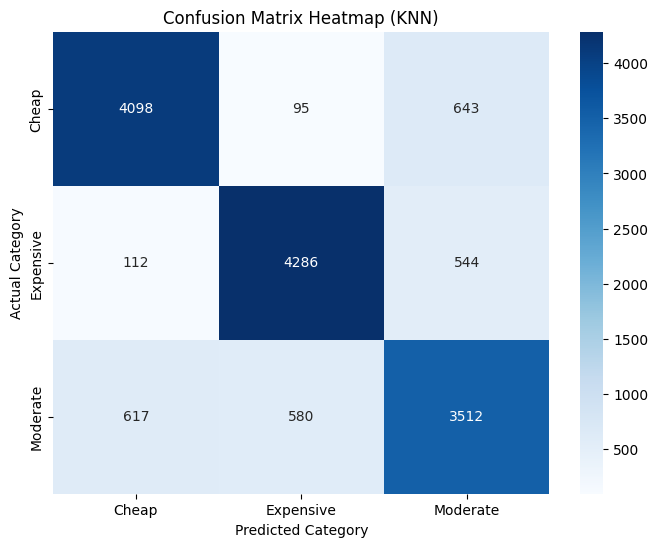

In [ ]:
cm = confusion_matrix(y_test_class, y_pred_class)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.title('Confusion Matrix Heatmap (KNN)')
plt.show()

# Task 6 Analysis and Discussion

## Model Comparison
### 1-Which model performed better, and what does better mean in each context?
#### in linear Regression we can Determination the performance Through MSE and R^2 score Regarding in KNN we can Determination the performance through F-1 score The model that performed better in the classification task is KNN because the MSE in linear regression is MSE  = 0.4086946569534182 ,R-score =0.6040975836106951 and in KNN the F-1 score is 0.82012623908766
### 2-Is classification easier than regression on this dataset? Why or why not?
#### Classification is easier because converting prices into categories reduces the effect of noise ,the linear regression is prediction the real price its more difficult but classfiction He collects data that are similar In one category
### 3-Does converting price into categories lose important information?
#### Yes, converting price into categories results in Information Loss, specifically losing the exact distance between data points and creating artificial boundaries. However, it simplifies the problem by reducing noise and making the model more robust against outliers, which is often more useful for business categorization

## Sensitivity Analysis
### 1-What happens if you remove the most correlated feature? Does performance drop a lot?
#### If the most correlated feature is removed, the impact on performance depends on the presence of Multicollinearity in the dataset:
Performance Drop: If the feature contains unique information that no other variable provides, the performance (Accuracy or R-squared) will drop significantly because the model loses its primary "signal."
Redundancy & Recovery: In many real estate datasets, features like 'Square Footage' and 'Number of Rooms' are highly correlated with each other. If we remove one, the other can often act as a "proxy" and carry the missing information. In this case, the performance might only drop slightly.
Model Robustness: Removing the most correlated feature can sometimes be beneficial as it reduces the risk of Overfitting and makes the model more robust when dealing with new, unseen data.
### 2-Try running KNN without scaling — how much does performance change?
#### Running KNN without scaling would significantly degrade performance. Since KNN is a distance-based algorithm, features with large numerical ranges (like mileage) will dominate the distance calculation, causing the model to ignore smaller-scale features (like engineSize). This leads to a biased model and a lower overall F1-score
### 3-Try a different threshold for your price categories — does KNN accuracy change significantly?
#### Yes, changing the price thresholds will significantly affect KNN accuracy. If the thresholds create imbalanced classes, accuracy may artificially increase while the model's ability to identify smaller classes (Recall) drops. Furthermore, if thresholds are placed in areas where feature distributions overlap, the decision boundaries become fuzzy, leading to a drop in overall performance.

## Task 7

### visualization

#### scatter plot reveals which category has a higher mpg ( save more fuel )

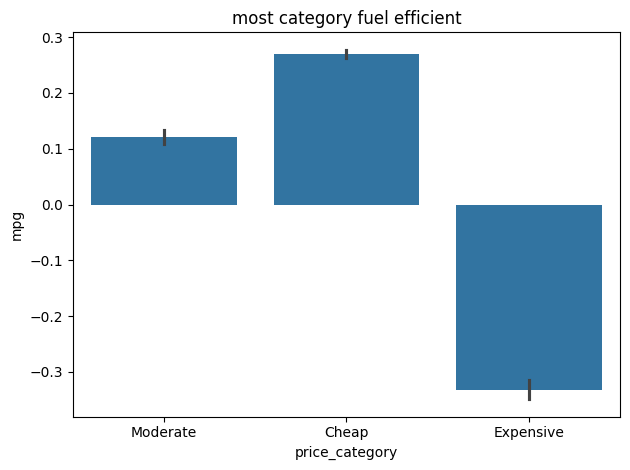

In [ ]:
df_corr= pd.concat([X_train,y_df], axis=1 )

sns.barplot(x= 'price_category',y= 'mpg', data= df_corr)
plt.title('most category fuel efficient')
plt.tight_layout()
plt.show()

#### line plot explains what happen to taxes across years

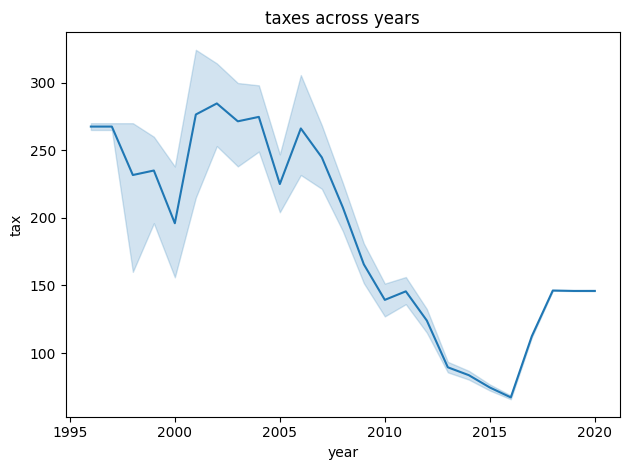

In [ ]:
sns.lineplot(x= 'year',y= 'tax', data= df)
plt.title('taxes across years')
plt.tight_layout()
plt.show()

#### bar plot reveals which transmission has the highest price

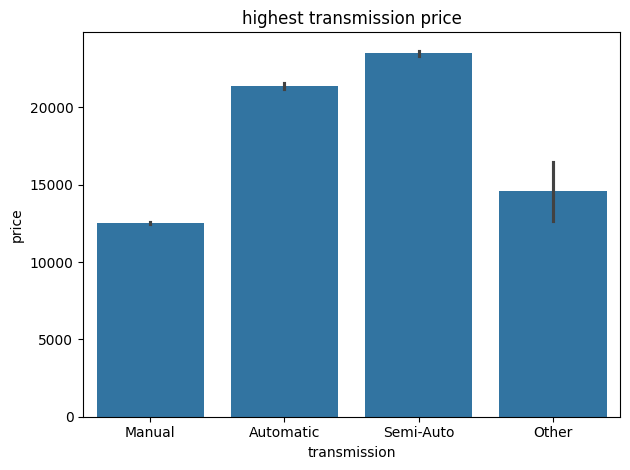

In [ ]:
plt.Figure(figsize= (15,10))
sns.barplot(x= 'transmission',y= 'price', data= df)
plt.title('highest transmission price')
plt.tight_layout()
plt.show()